# Task 2: Unsupervised learning (K-means clustering and association rules)

Two ways of looking for structure in the hourly traffic data **without a target to predict**:

1. **K-means** groups hours with similar conditions (hour of day, weekend flag, weather severity, traffic volume).
2. **Association rules** find combinations of time of day, day type and weather that go with a congestion level, ranked by *lift*.

**Data source: no real accident dataset was sourced**, so both analyses describe *traffic conditions*, not accidents. Congestion level is the Part 3 quartile `congestion_category` (Low / Medium / High / Severe), which is derived from `traffic_volume`; volume is also a K-means feature, so clusters partly reflect congestion by construction. Findings are associations, not causes.

The code lives in `../unsupervised_models.py`; this notebook reuses it so results match the script and MLflow.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PART_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(PART_DIR))
import unsupervised_models as um

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
LOG = logging.getLogger("task2_notebook")
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_colwidth = 200
plt.rcParams["figure.dpi"] = 100

## 1. Load data and run the analysis

- Reads the labelled CSV and runs the same pipeline as `unsupervised_models.py`: build the K-means features, score k = 2 to 10, fit the chosen k, profile the clusters and mine the rules.
- **Weather severity** reuses the Part 3 weather groups: 0 = other (Clear, Clouds, Rain, Drizzle), 1 = low visibility (Fog, Mist, Haze, Smoke), 2 = severe (Thunderstorm, Snow, Squall).
- All five K-means features are standardised (mean 0, spread 1) so that volume, in the thousands, does not swamp the others.

In [2]:
raw = pd.read_csv(PART_DIR / "data" / "processed" / "Metro_Interstate_Traffic_Volume_ml.csv", encoding="utf-8-sig")
k_table, model, profile, df, rules, info = um.run_analysis(raw, um.DEFAULT_K, min_support=0.01, min_confidence=0.5)
LOG.info("Chosen k = %d; %d rules mined.", info["k"], len(rules))
df[list(um.KMEANS_FEATURES)].describe().T[["mean", "std", "min", "max"]]

2026-11-15 16:46:14,388 INFO unsupervised_models: k=2: inertia=141341, silhouette=0.314.


2026-11-15 16:46:15,937 INFO unsupervised_models: k=3: inertia=112738, silhouette=0.348.


2026-11-15 16:46:17,436 INFO unsupervised_models: k=4: inertia=89438, silhouette=0.379.


2026-11-15 16:46:19,099 INFO unsupervised_models: k=5: inertia=75767, silhouette=0.392.


2026-11-15 16:46:20,614 INFO unsupervised_models: k=6: inertia=61294, silhouette=0.393.


2026-11-15 16:46:22,117 INFO unsupervised_models: k=7: inertia=51611, silhouette=0.412.


... (2 outputs left out)

2026-11-15 16:46:27,106 INFO unsupervised_models: k=10: inertia=36788, silhouette=0.431.


2026-11-15 16:46:27,497 INFO unsupervised_models: 44 rules pass support>=0.010 and confidence>=0.50; 14 add information over simpler rules.


2026-11-15 16:46:27,498 INFO task2_notebook: Chosen k = 6; 44 rules mined.


,mean,std,min,max
hour_sin,-0.002,0.706,-1.000,1.000
hour_cos,0.005,0.708,-1.000,1.000
is_weekend,0.286,0.452,0.000,1.000
weather_severity,0.235,0.562,0.000,2.000
traffic_volume,"3,290.650","1,984.773",0.000,"7,280.000"


## 2. K-means: choosing the number of clusters

- **Elbow (left):** total within-cluster distance (inertia) always falls as k grows; look for where the drop slows.
- **Silhouette (right):** how well separated the clusters are (higher is better, max 1). It is computed on a 10,000-hour sample for speed.
- Silhouette keeps edging up to k = 9, but it is flat between k = 5 and 6 and the extra clusters are harder to describe. **k = 6 was chosen for interpretability** (a judgement call, marked on the plots).

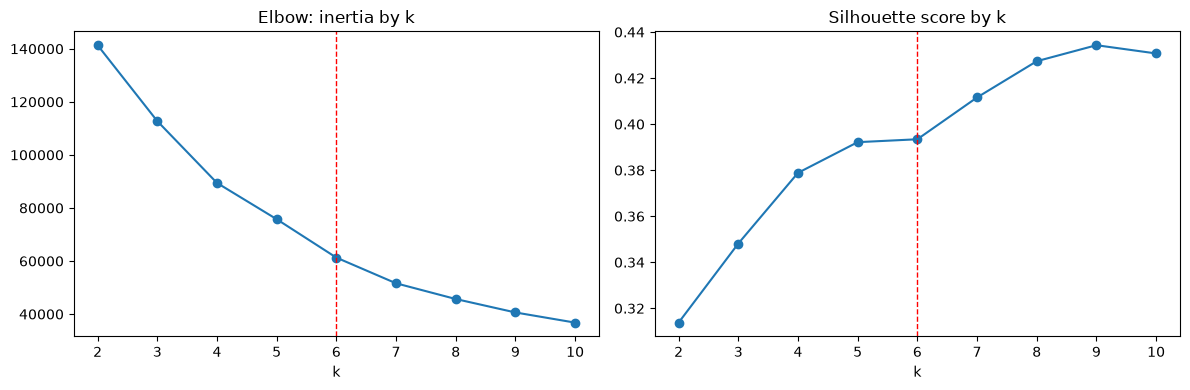

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k_table.plot(x="k", y="inertia", marker="o", ax=axes[0], legend=False, title="Elbow: inertia by k")
k_table.plot(x="k", y="silhouette", marker="o", ax=axes[1], legend=False, title="Silhouette score by k")
for ax in axes:
    ax.axvline(info["k"], color="red", ls="--", lw=1)
plt.tight_layout()
plt.show()

## 3. K-means: what does each cluster represent?

Clusters are numbered from the lowest to the highest average traffic volume. The table summarises each cluster: its size, average volume, the hours it most often covers, the weekend and weather shares, the share of proxy `high_risk` hours and its mix of congestion levels.

In [4]:
profile

,hours,share,mean_volume,most_common_hours,weekend_share,low_visibility_share,severe_weather_share,high_risk_share,share_Low,share_Medium,share_High,share_Severe
cluster,,,,,,,,,,,,
0,5120,0.126,"1,226.590","0, 1, 5, 23",1.000,0.147,0.000,0.001,0.593,0.404,0.003,0.000
1,10260,0.253,"1,266.905","0, 4, 22, 23",0.000,0.132,0.000,0.000,0.616,0.379,0.006,0.000
2,2753,0.068,"2,998.259","1, 2, 3, 10",0.268,0.001,0.999,0.446,0.282,0.273,0.268,0.178
3,5738,0.141,"3,914.181","10, 12, 13, 14",1.000,0.064,0.000,0.044,0.002,0.262,0.677,0.059
4,8907,0.220,"4,848.187","14, 16, 18, 19",0.000,0.040,0.000,0.032,0.000,0.197,0.276,0.527
5,7797,0.192,"5,174.165","8, 10, 11, 12",0.000,0.156,0.000,0.153,0.001,0.024,0.384,0.592


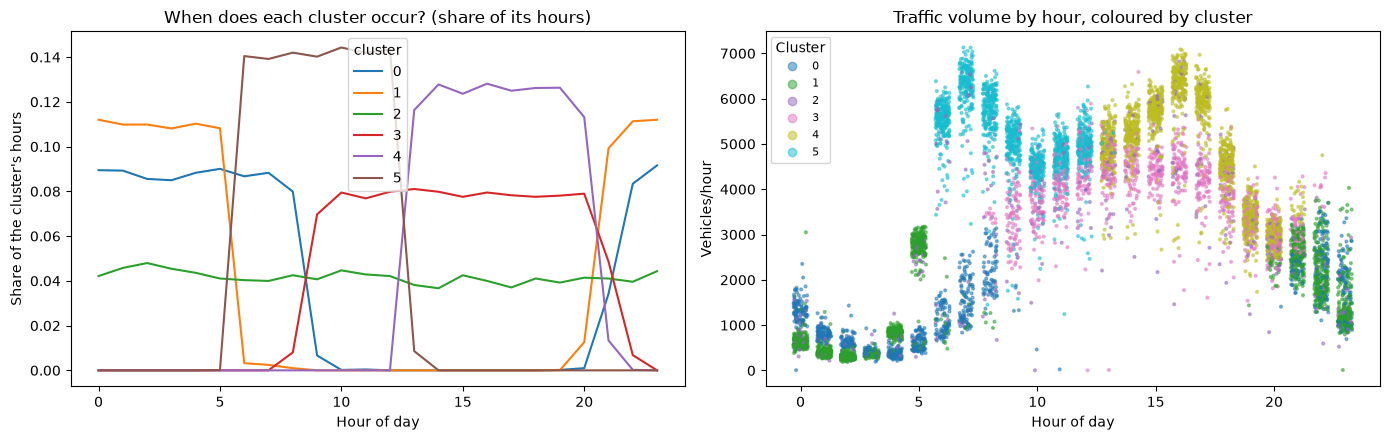

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
hours = pd.crosstab(df["cluster"], df["hour"], normalize="index")
hours.T.plot(ax=axes[0], title="When does each cluster occur? (share of its hours)")
axes[0].set(xlabel="Hour of day", ylabel="Share of the cluster's hours")
sample = df.sample(8000, random_state=um.RANDOM_STATE)
scatter = axes[1].scatter(
    sample["hour"] + np.random.default_rng(0).uniform(-0.3, 0.3, len(sample)),
    sample["traffic_volume"], c=sample["cluster"], cmap="tab10", s=4, alpha=0.5,
)
axes[1].set(title="Traffic volume by hour, coloured by cluster", xlabel="Hour of day", ylabel="Vehicles/hour")
axes[1].legend(*scatter.legend_elements(), title="Cluster", loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

### Interpretation of the six clusters

| Cluster | Label | What it represents |
|---|---|---|
| 0 | **Weekend night** | All weekend, mostly 23:00-05:00; about 1,200 vehicles/hour; almost never High or Severe congestion. |
| 1 | **Weekday night** | All weekday, mostly 22:00-04:00; about 1,300 vehicles/hour; the biggest group (25% of hours); Low or Medium congestion. |
| 2 | **Severe-weather hours** | Essentially every Thunderstorm, Snow or Squall hour at any time of day and about 3,000 vehicles/hour; congestion is spread over all four levels, and 45% of these hours are proxy `high_risk`. |
| 3 | **Weekend daytime** | All weekend, mostly 10:00-14:00; about 3,900 vehicles/hour; mostly High congestion (68%). |
| 4 | **Weekday afternoon / evening** | Weekdays, mostly 14:00-19:00; about 4,800 vehicles/hour; half the hours are Severe congestion. |
| 5 | **Weekday morning to midday** | Weekdays, mostly 08:00-12:00; the highest average (about 5,200 vehicles/hour); 59% Severe congestion. |

Notes:
- Weekday/weekend and the daily cycle drive the clusters, as expected from the project findings that time of day dominates traffic.
- Only the rare **severe** weather forms its own cluster (it is a minority and stands out after standardising). **Low-visibility** hours do not: they are spread (about 4-16%) across the time-based clusters, so they do not define a separate traffic regime.
- Cluster 2 groups by weather, not by traffic level, so it mixes quiet and busy hours; its high `high_risk` share is largely by construction of the proxy label.
- K-means assumes round, similar-sized groups and the result depends on the feature scaling and on k. Treat the labels as descriptions, not ground truth.

## 4. Association rules: setting up

Each hour is turned into three descriptive *items* plus its congestion level:

- **Time of day:** Night 00-05, Morning 06-11, Afternoon 12-17, Evening 18-23.
- **Day type:** Weekday or Weekend.
- **Weather group:** Clear, Clouds, Rain/Drizzle, Low visibility (Fog, Mist, Haze, Smoke) or Severe weather (Thunderstorm, Snow, Squall).
- **Congestion level:** Low, Medium, High or Severe (quartiles of traffic volume, so each is about 25% of hours).

A rule reads "if these conditions hold, then this congestion level". Three numbers describe it:
- **Support:** the share of all hours matching both sides (how common).
- **Confidence:** among hours matching the conditions, the share with that congestion level (how reliable).
- **Lift:** confidence divided by the overall share of that level. 1 means no link; 3 means three times as likely as usual. Because each level is about 25% of hours, lift cannot exceed about 4.

Rules are kept if support is at least 1% and confidence at least 50%, then ranked by lift. Rare combinations (under 1% of hours, for example Fog or Smoke) are dropped by the support threshold.

In [6]:
items = um.rule_items(df)
LOG.info("Rules passing thresholds: %d (%d add information).", len(rules), rules["adds_information"].sum())
items.apply(lambda c: c.value_counts(normalize=True)).T.fillna(0).round(3)

2026-11-15 16:46:28,318 INFO task2_notebook: Rules passing thresholds: 44 (14 add information).


,Afternoon,Clear,Clouds,Evening,High,Low,Low visibility,Medium,Morning,Night,Rain/Drizzle,Severe,Severe weather,Weekday,Weekend
time_of_day,0.249,0.000,0.000,0.252,0.000,0.000,0.000,0.000,0.248,0.251,0.000,0.000,0.000,0.000,0.000
day_type,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.714,0.286
weather_group,0.000,0.329,0.373,0.000,0.000,0.000,0.100,0.000,0.000,0.000,0.130,0.000,0.068,0.000,0.000
congestion,0.000,0.000,0.000,0.000,0.250,0.250,0.000,0.250,0.000,0.000,0.000,0.250,0.000,0.000,0.000


## 5. Rules with the highest lift

Many rules are near-duplicates (for example every "Night & ... -> Low" rule has about the same confidence as plain "Night -> Low"). To keep the list readable, a rule is flagged `adds_information` only if it is at least 2 percentage points more confident than every simpler rule (`MIN_CONFIDENCE_GAIN` in the script; all rules remain in `association_rules.csv`). The table shows the top rules that add information.

In [7]:
top = rules[rules["adds_information"]].head(10)
top[["antecedent", "congestion", "support", "confidence", "lift", "confidence_gain"]].reset_index(drop=True)

,antecedent,congestion,support,confidence,lift,confidence_gain
0,Night & Weekend,Low,0.064,0.896,3.585,0.043
1,Night,Low,0.214,0.853,3.413,0.603
2,Afternoon & Weekend,High,0.060,0.835,3.341,0.430
3,Afternoon & Weekday & Clouds,Severe,0.065,0.774,3.097,0.025
4,Afternoon & Weekday & Clear,Severe,0.037,0.774,3.096,0.025
5,Afternoon & Weekday,Severe,0.133,0.749,2.995,0.184
6,Morning & Weekday & Low visibility,Severe,0.018,0.694,2.777,0.102
7,Evening & Severe weather,Medium,0.011,0.679,2.716,0.021
8,Evening,Medium,0.166,0.658,2.630,0.408
9,Morning & Weekday & Rain/Drizzle,Severe,0.015,0.617,2.468,0.024


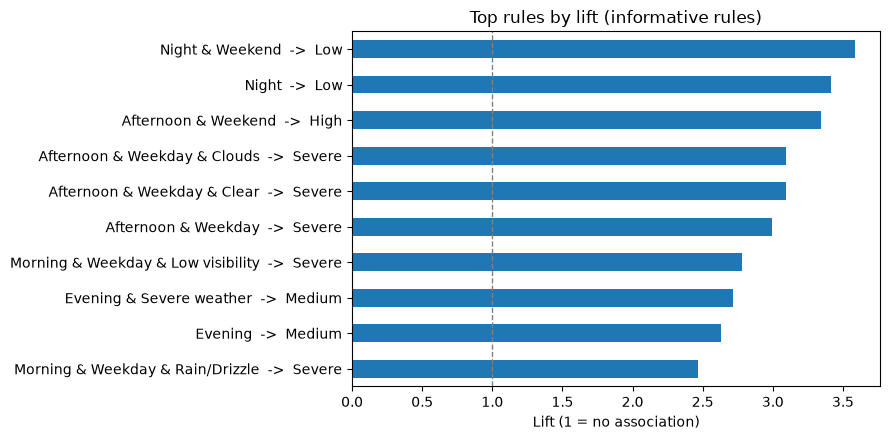

In [8]:
labels = top["antecedent"] + "  ->  " + top["congestion"]
ax = pd.Series(top["lift"].values, index=labels).iloc[::-1].plot.barh(figsize=(9, 4.5), title="Top rules by lift (informative rules)")
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("Lift (1 = no association)")
plt.tight_layout()
plt.show()

### The same rules in plain language

Each sentence is generated from the rule's numbers, with the hours it is based on.

In [9]:
for i, text in enumerate(top["meaning"], start=1):
    LOG.info("Rule %d: %s", i, text)

2026-11-15 16:46:28,509 INFO task2_notebook: Rule 1: For Night & Weekend hours, 90% have Low congestion, versus 25% of all hours (3.6x as likely); 2,611 hours.


2026-11-15 16:46:28,510 INFO task2_notebook: Rule 2: For Night hours, 85% have Low congestion, versus 25% of all hours (3.4x as likely); 8,692 hours.


2026-11-15 16:46:28,510 INFO task2_notebook: Rule 3: For Afternoon & Weekend hours, 84% have High congestion, versus 25% of all hours (3.3x as likely); 2,420 hours.


2026-11-15 16:46:28,510 INFO task2_notebook: Rule 4: For Afternoon & Weekday & Clouds hours, 77% have Severe congestion, versus 25% of all hours (3.1x as likely); 2,655 hours.


2026-11-15 16:46:28,511 INFO task2_notebook: Rule 5: For Afternoon & Weekday & Clear hours, 77% have Severe congestion, versus 25% of all hours (3.1x as likely); 1,492 hours.


2026-11-15 16:46:28,511 INFO task2_notebook: Rule 6: For Afternoon & Weekday hours, 75% have Severe congestion, versus 25% of all hours (3.0x as likely); 5,389 hours.


2026-11-15 16:46:28,512 INFO task2_notebook: Rule 7: For Morning & Weekday & Low visibility hours, 69% have Severe congestion, versus 25% of all hours (2.8x as likely); 740 hours.


2026-11-15 16:46:28,512 INFO task2_notebook: Rule 8: For Evening & Severe weather hours, 68% have Medium congestion, versus 25% of all hours (2.7x as likely); 461 hours.


2026-11-15 16:46:28,512 INFO task2_notebook: Rule 9: For Evening hours, 66% have Medium congestion, versus 25% of all hours (2.6x as likely); 6,731 hours.


2026-11-15 16:46:28,512 INFO task2_notebook: Rule 10: For Morning & Weekday & Rain/Drizzle hours, 62% have Severe congestion, versus 25% of all hours (2.5x as likely); 591 hours.


### What the rules say

- **Time of day and day type explain most of it.** Night hours are Low congestion about 85% of the time (89-90% at weekends); weekend afternoons are High congestion about 84% of the time; weekday afternoons and mornings are Severe congestion 75% and 59% of the time; evenings are mostly Medium.
- **Weather adds little.** Of the 44 rules, only 14 beat every simpler rule by 2 percentage points, and the weather-specific ones among them gain just 2-3 points over the plain time-and-day rule. The largest exception is weekday mornings with low visibility (69% Severe vs 59% for all weekday mornings, 740 hours); severe-weather evenings (68% Medium vs 66%, 461 hours) are a small gain. These rest on a modest number of hours and are associations, not causes.
- **Few rules for High congestion.** Only 3 of the 44 rules (one of them informative: weekend afternoons) have High as the outcome, because High is a middle band of volume and spreads across several time bands.
- The congestion levels are quartiles of volume computed on all rows, so rules link time and weather to *relative* congestion in this dataset.

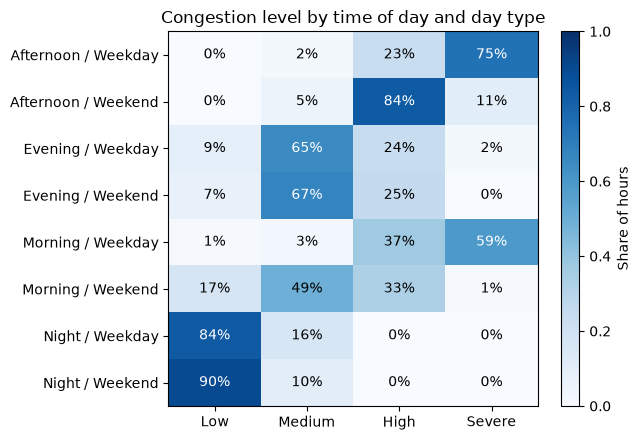

In [10]:
slots = items["time_of_day"] + " / " + items["day_type"]
share = pd.crosstab(slots, items["congestion"], normalize="index")[list(um.CONGESTION_LEVELS)]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
image = ax.imshow(share.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(share.shape[1]), share.columns)
ax.set_yticks(range(share.shape[0]), share.index)
for (row, col), value in np.ndenumerate(share.values):
    ax.text(col, row, f"{value:.0%}", ha="center", va="center", color="white" if value > 0.5 else "black")
ax.set_title("Congestion level by time of day and day type")
fig.colorbar(image, label="Share of hours")
plt.tight_layout()
plt.show()

## 6. Logged MLflow run

Created by `python Part-3/unsupervised_models.py`; it logs the K-means model, the chosen k, silhouette, inertia, rule count and the output CSVs under the experiment `task2-unsupervised-models`.

In [11]:
import mlflow

mlflow.set_tracking_uri(f"sqlite:///{(PART_DIR / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["task2-unsupervised-models"]).set_index("tags.mlflow.runName")
runs[[c for c in runs.columns if c.startswith("metrics.") or c == "params.k"]]

,metrics.n_rules,metrics.inertia,metrics.silhouette,params.k
tags.mlflow.runName,,,,
kmeans k=6 + association rules,44.000,"61,293.647",0.393,6


## 7. Observations

- Six clusters separate weekend/weekday and the daily cycle (night, weekend daytime, weekday afternoon/evening, weekday morning-midday) plus one severe-weather cluster.
- Only severe weather forms its own cluster; low-visibility hours are spread across the time-based clusters.
- Rule mining agrees: time of day and day type predict congestion level strongly (lift up to about 3.6), weather adds little.
- Choice of k = 6 is a judgement (silhouette is highest at k = 9); congestion levels are derived from volume, which is also a clustering feature.
- No accident data was used; these describe traffic conditions only. Squall, Smoke and Fog are too rare to appear in the rules, and coverage across years is uneven.